# Assignment 2 — Autoencoder Anomaly Detection

This notebook runs the full pipeline by importing the modular code in `assignment_2/`.


In [4]:
from pathlib import Path
import sys

repo = Path.cwd()
if (repo / "assignment_2").exists():
    project_root = repo
elif (repo.parent / "assignment_2").exists():
    project_root = repo.parent
else:
    project_root = repo

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("project_root:", project_root)

project_root: /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025


In [6]:
import os, sys, shutil, subprocess
print(sys.executable)
print(sys.version)

import torch
print("torch", torch.__version__)
print("cuda", torch.version.cuda)
print("cuda available", torch.cuda.is_available())
print("python", ".".join(map(str, sys.version_info[:3])))

cuda = "/home/hhdel/.local/cuda-12.1"
os.environ["CUDA_HOME"] = cuda
os.environ["PATH"] = f"{cuda}/bin:" + os.environ["PATH"]
os.environ["LD_LIBRARY_PATH"] = f"{cuda}/lib64:" + os.environ.get("LD_LIBRARY_PATH","")

print("python", ".".join(map(str, sys.version_info[:3])))

/home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/.venv/bin/python
3.11.9 (main, Aug 14 2024, 05:07:28) [Clang 18.1.8 ]
torch 2.3.1+cu121
cuda 12.1
cuda available True
python 3.11.9
python 3.11.9


In [7]:
from pathlib import Path
import json
import numpy as np
import torch

repo = Path.cwd()
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from assignment_2.data import (
    load_mnist,
    default_transforms,
    build_dataloaders,
    make_corrupted_subset,
    stratified_indices,
)
from assignment_2.models import SimpleAutoencoder, DeepAutoencoder, ConvAutoencoder
from assignment_2.training import train_autoencoder_sgd, evaluate_anomaly_detection, save_metrics_json
from assignment_2.visualization import (
    plot_original_corrupted,
    plot_reconstructions,
    plot_loss_curves,
    plot_loss_comparison,
    plot_error_distribution,
    plot_confusion_matrix,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


In [8]:
output_dir = repo / "assignment_2" / "output_notebook"
output_dir.mkdir(parents=True, exist_ok=True)

epochs = 50
batch_size = 64
val_frac = 0.2
noise_level = 0.8
noise_type = "gaussian"
corrupt_fraction = 0.1


Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:10<00:00, 918266.29it/s] 


Extracting /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw/train-images-idx3-ubyte.gz to /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 275959.41it/s]


Extracting /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw/train-labels-idx1-ubyte.gz to /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:00<00:00, 3029095.45it/s]


Extracting /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw/t10k-images-idx3-ubyte.gz to /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 9568321.83it/s]


Extracting /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw/t10k-labels-idx1-ubyte.gz to /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/data/MNIST/raw



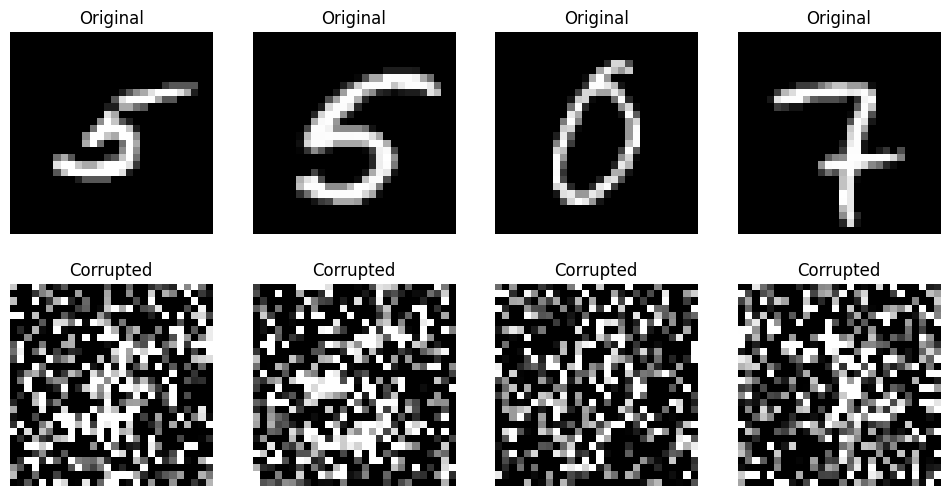

In [9]:
mnist_train, mnist_test = load_mnist(repo / "data")
transform_train, transform_val = default_transforms()

train_idx, val_idx = stratified_indices(mnist_train.targets, val_frac=val_frac)
train_loader, val_loader = build_dataloaders(
    mnist_train,
    train_idx,
    val_idx,
    batch_size=batch_size,
    transform_train=transform_train,
    transform_val=transform_val,
    num_workers=4,
    pin_memory=True,
)

clean_ds, corrupt_ds = make_corrupted_subset(
    mnist_test,
    fraction=corrupt_fraction,
    noise_type=noise_type,
    noise_level=noise_level,
)

plot_original_corrupted(clean_ds, corrupt_ds, n=4)


In [10]:
models = {
    "simple_linear": SimpleAutoencoder(),
    "deep_linear": DeepAutoencoder(),
    "conv": ConvAutoencoder(),
}

histories = {}
for name, model in models.items():
    model_out = output_dir / name
    model_out.mkdir(parents=True, exist_ok=True)
    history = train_autoencoder_sgd(
        model,
        train_loader,
        val_loader,
        epochs=epochs,
        device=device,
        lr=1e-2,
        loss_fn="mse",
    )
    histories[name] = history
    torch.save(model.state_dict(), model_out / "model_mse.pth")
    save_metrics_json({"loss": history, "model": name, "loss_name": "mse"}, model_out / "train_mse.json")
    plot_loss_curves(history, title=f"{name} mse loss", save_path=model_out / "train_mse.png")
    plot_reconstructions(model, clean_ds, corrupt_ds, device=device, n=4, save_path=model_out / "reconstructions.png")

print("trained:", list(histories))


Epoch 1/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.231469 | Val Loss: 0.231033


Epoch 2/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 0.230725 | Val Loss: 0.230280


Epoch 3/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 3 | Train Loss: 0.230000 | Val Loss: 0.229533


... (290 outputs left out)

Epoch 49/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 49 | Train Loss: 0.095324 | Val Loss: 0.094975


Epoch 50/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 50 | Train Loss: 0.095244 | Val Loss: 0.094967
trained: ['simple_linear', 'deep_linear', 'conv']


In [11]:
ssim_model = SimpleAutoencoder()
ssim_history = train_autoencoder_sgd(
    ssim_model,
    train_loader,
    val_loader,
    epochs=epochs,
    device=device,
    lr=1e-2,
    loss_fn="ssim",
)

torch.save(ssim_model.state_dict(), output_dir / "simple_linear" / "model_ssim.pth")
save_metrics_json(
    {"loss": ssim_history, "model": "simple_linear", "loss_name": "ssim"},
    output_dir / "simple_linear" / "train_ssim.json",
)
plot_loss_comparison(
    histories["simple_linear"],
    ssim_history,
    save_path=output_dir / "simple_linear" / "loss_mse_vs_ssim.png",
)


Epoch 1/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.994764 | Val Loss: 0.992858


Epoch 2/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 2 | Train Loss: 0.992125 | Val Loss: 0.989813


Epoch 3/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 3 | Train Loss: 0.989373 | Val Loss: 0.986520


... (90 outputs left out)

Epoch 49/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 49 | Train Loss: 0.582905 | Val Loss: 0.518934


Epoch 50/50 [Train]:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch 50 | Train Loss: 0.581952 | Val Loss: 0.518370


best model: deep_linear


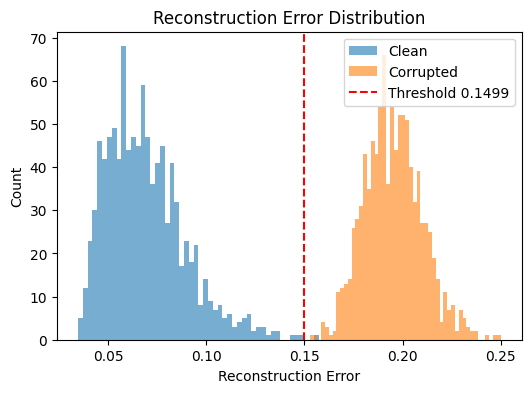

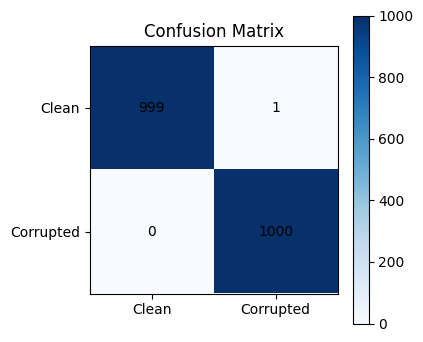

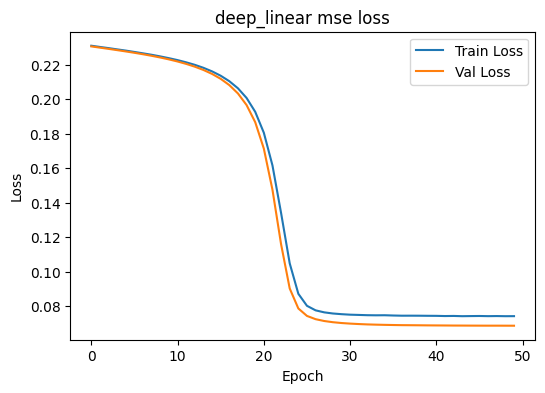

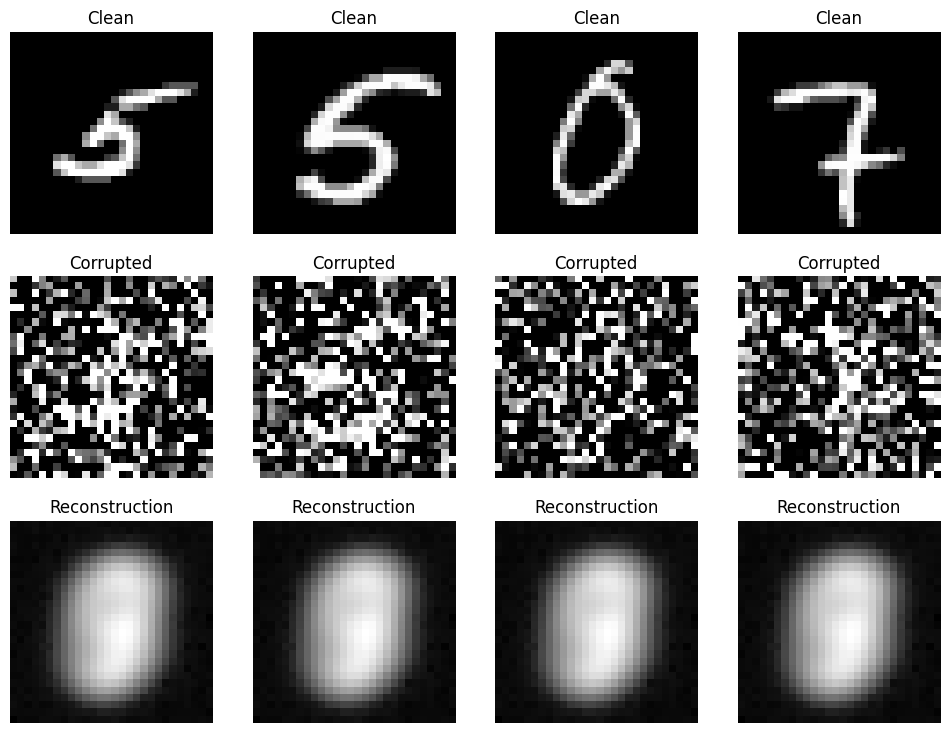

In [12]:
def select_best_model(histories_dict):
    best_name, best_loss = None, None
    for name, hist in histories_dict.items():
        if not hist["val_loss"]:
            continue
        loss = hist["val_loss"][-1]
        if best_loss is None or loss < best_loss:
            best_loss = loss
            best_name = name
    return best_name

best_name = select_best_model(histories)
best_model = models[best_name]
print("best model:", best_name)

clean_loader = torch.utils.data.DataLoader(
    clean_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)
corrupt_loader = torch.utils.data.DataLoader(
    corrupt_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

anomaly_metrics, clean_errors, corrupt_errors = evaluate_anomaly_detection(
    best_model,
    clean_loader,
    corrupt_loader,
    device=device,
)

save_metrics_json(
    {"best_model": best_name, "anomaly_metrics": anomaly_metrics},
    output_dir / "anomaly_metrics.json",
)

plot_error_distribution(
    clean_errors.numpy(),
    corrupt_errors.numpy(),
    threshold=anomaly_metrics["threshold"],
)

cm = np.array(
    [
        [anomaly_metrics["tn"], anomaly_metrics["fp"]],
        [anomaly_metrics["fn"], anomaly_metrics["tp"]],
    ]
)
plot_confusion_matrix(cm)

plot_loss_curves(histories[best_name], title=f"{best_name} mse loss")
plot_reconstructions(best_model, clean_ds, corrupt_ds, device=device, n=4)


In [13]:
print("outputs saved to", output_dir)


outputs saved to /home/hhdel/repos/computerVision_3D_data/cv_assignments_2025/assignment_2/assignment_2/output_notebook
